In [2]:
# Load required libraries:

import os 
import pandas_datareader.data as web
import yfinance as yf
import pandas as pd
import numpy as np
import talib as ta
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [8]:
os.getcwd()

'/home/ba/Bureau/DEV/Reinforment Leanring For Stocks/notebooks'

In [3]:
data_path = '../data/'

join_data_path = lambda *args: os.path.join(data_path, *args)

In [4]:


# Define asset symbols:
assets = {
    "EUR/USD": "EURUSD=X",   # EUR/USD exchange rate
    "Gold": "GC=F",          # Gold futures
    "Oil": "CL=F", # Crude Oil futures
    "Vix":"^VIX"            
}

# Fetch historical data
df_forex = {name: yf.Ticker(symbol).history(period="3y") for name, symbol in assets.items()}

# Save to a file
#df_forex.to_csv("dforex.data")


# Combine all DataFrames into one, adding a column for the market name
df_combined = pd.concat([df.assign(Market=key) for key, df in df_forex.items()])

# Save to a single CSV file
df_combined.to_csv(join_data_path("data_forex.csv"), index=False)



df_combined = pd.concat(
    [df.reset_index().assign(Market=key) for key, df in df_forex.items()],
    ignore_index=True
)

df_combined.to_csv(join_data_path("data_forex.csv"), index=False)

df_combined.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Market
0,2023-11-13 00:00:00+00:00,1.069016,1.070549,1.066553,1.069016,0,0.0,0.0,EUR/USD
1,2023-11-14 00:00:00+00:00,1.070183,1.086720,1.069359,1.070183,0,0.0,0.0,EUR/USD
2,2023-11-15 00:00:00+00:00,1.087831,1.088732,1.083295,1.087831,0,0.0,0.0,EUR/USD
3,2023-11-16 00:00:00+00:00,1.085458,1.089396,1.083095,1.085458,0,0.0,0.0,EUR/USD
4,2023-11-17 00:00:00+00:00,1.085376,1.089230,1.082520,1.085376,0,0.0,0.0,EUR/USD


In [5]:


def calculate_eurusd_indicators(stock_data):
    try:
        if stock_data is None or stock_data.empty:
            print("Error: EUR/USD data not available.")
            return None

        # Convert necessary columns to float
        close_prices = stock_data["Close"].astype(np.float64)
        high_prices = stock_data["High"].astype(np.float64)
        low_prices = stock_data["Low"].astype(np.float64)

        # Compute technical indicators
        data = {
            "MACD": ta.MACD(close_prices)[0].tolist(),
            "RSI": ta.RSI(close_prices).tolist(),
            "CCI": ta.CCI(high_prices, low_prices, close_prices).tolist(),
            "ADX": ta.ADX(high_prices, low_prices, close_prices).tolist(),
            "STOCH_K": ta.STOCH(high_prices, low_prices, close_prices)[0].tolist(),
            "WILLR": ta.WILLR(high_prices, low_prices, close_prices).tolist(),
            "BB_Upper": ta.BBANDS(close_prices)[0].tolist(),
            "BB_Middle": ta.BBANDS(close_prices)[1].tolist(),
            "BB_Lower": ta.BBANDS(close_prices)[2].tolist(),
            "EMA": ta.EMA(close_prices).tolist(),
            "ATR": ta.ATR(high_prices, low_prices, close_prices).tolist(),
            "SAR": ta.SAR(high_prices, low_prices).tolist(),
            "Close_Lag1": close_prices.shift(1).tolist(),
            "Close_Lag3": close_prices.shift(3).tolist(),
            "Close_Lag5": close_prices.shift(5).tolist(),
            "SMA_50": close_prices.rolling(window=50).mean().tolist(),
            "SMA_20": close_prices.rolling(window=20).mean().tolist(),
            "STD_10": close_prices.rolling(window=10).std().tolist(),
            "STD_30": close_prices.rolling(window=30).std().tolist(),
        }

        # Convert the data dictionary to a DataFrame
        indicators_df = pd.DataFrame(data)
        return indicators_df

    except Exception as e:
        print(f"An error occurred: {e}")
        return None


                        Date      Open      High       Low     Close  Volume  \
0  2023-11-13 00:00:00+00:00  1.069016  1.070549  1.066553  1.069016       0   
1  2023-11-14 00:00:00+00:00  1.070183  1.086720  1.069359  1.070183       0   
2  2023-11-15 00:00:00+00:00  1.087831  1.088732  1.083295  1.087831       0   
3  2023-11-16 00:00:00+00:00  1.085458  1.089396  1.083095  1.085458       0   
4  2023-11-17 00:00:00+00:00  1.085376  1.089230  1.082520  1.085376       0   

   Dividends  Stock Splits   Market  
0        0.0           0.0  EUR/USD  
1        0.0           0.0  EUR/USD  
2        0.0           0.0  EUR/USD  
3        0.0           0.0  EUR/USD  
4        0.0           0.0  EUR/USD  
       MACD        RSI        CCI        ADX    STOCH_K      WILLR  BB_Upper  \
0  0.000257  67.216333  67.546895  23.044804  43.937578 -11.564978  0.004878   
1  0.000257  67.216333  67.546895  23.044804  43.937578 -11.564978  0.004878   
2  0.000257  67.216333  67.546895  23.044804  43.93

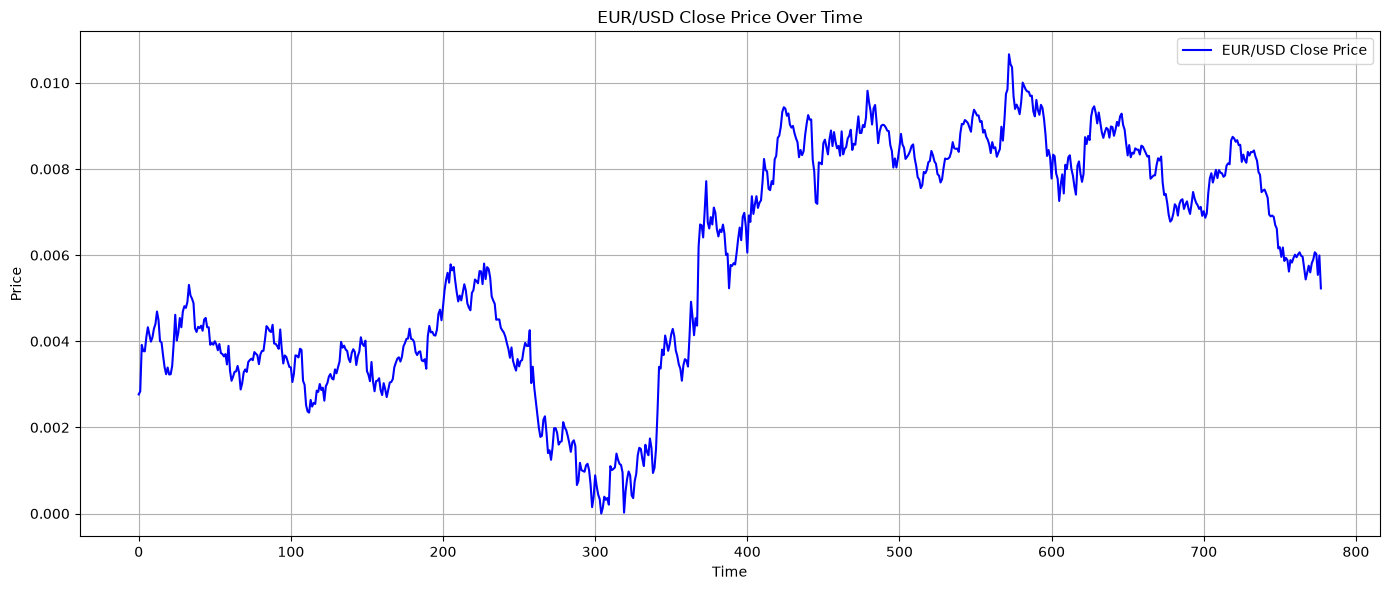

In [6]:
# Read the CSV file into a DataFrame:
Forex_df = pd.read_csv(join_data_path("data_forex.csv"))

# Display the first few rows:
print(Forex_df.head())
combined_df=Forex_df
combined_df=combined_df.drop(columns=['Dividends','Stock Splits'])

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))  # Ensures small values remain positive

# Select numerical columns for normalization:
numeric_columns = ['Open', 'High', 'Low', 'Close', 'Volume']


# Apply normalization to relevant columns:
combined_df[numeric_columns] = np.log1p(combined_df[numeric_columns])  # Log transformation
combined_df[numeric_columns] = scaler.fit_transform(combined_df[numeric_columns])  # Normalize

# Display processed data
#print(combined_df.head())

# Extract  data :
eur_usd_df = combined_df[combined_df['Market'] == 'EUR/USD']
oil_df = combined_df[combined_df['Market'] == 'Oil']
gold_df = combined_df[combined_df['Market'] == 'Gold']
vix_df = combined_df[combined_df['Market'] == 'Vix']

# Calculate Target technical indicators:

indicators_df = calculate_eurusd_indicators(eur_usd_df)

indicators_df=indicators_df.bfill()
if indicators_df is not None:
    print(indicators_df.head())  # Display processed data
else:
    print("Failed to process EUR/USD data.")



# Compute the correlation matrix:
corr_matrix = indicators_df.corr().abs()

# Set a threshold for high correlation:
threshold = 0.9

# Identify  correlated columns to drop:
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]

# Drop highly correlated columns:
reduced_df = indicators_df.drop(columns=to_drop)

# Display remaining features:
#print(reduced_df.columns)

indicators_df=reduced_df

# Select numerical columns dynamically:
numeric_cols = indicators_df.select_dtypes(include=['number']).columns


scaler_indicators = StandardScaler()

indicators_df[numeric_cols] = scaler_indicators.fit_transform(indicators_df[numeric_cols])

indicators_df.to_csv(join_data_path("indicators_eurusd.csv"), index=False)
# Display processed data:
print(indicators_df.head())

plt.figure(figsize=(14, 6))
plt.plot(eur_usd_df['Close'], label='EUR/USD Close Price', color='blue')
plt.title('EUR/USD Close Price Over Time')
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [17]:
plotly_fig = px.line(eur_usd_df, x=eur_usd_df.index, y='Close', title='EUR/USD Close Price Over Time')
plotly_fig.update_layout(xaxis_title='Date', yaxis_title='Close Price', template='plotly_dark')
plotly_fig.show()

In [18]:
plotly_fig = px.line(eur_usd_df, x=eur_usd_df.Date, y='Close', title='EUR/USD Close Price Over Time')
plotly_fig.update_layout(xaxis_title='Date', yaxis_title='Close Price', template='plotly_dark')
plotly_fig.show()